In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv("D:\Projects-Guvi\EV\ChargingRecords.csv")

<>:1: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\P'
C:\Users\Jyots\AppData\Local\Temp\ipykernel_12584\2511024403.py:1: SyntaxWarning: invalid escape sequence '\P'
  df = pd.read_csv("D:\Projects-Guvi\EV\ChargingRecords.csv")


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), str(7)
memory usage: 12.5 MB


In [5]:
df.drop_duplicates(inplace=True)

In [6]:
df['StartDay'] = pd.to_datetime(df['StartDay']).dt.date
df['EndDay'] = pd.to_datetime(df['EndDay']).dt.date
df['StartTime'] = pd.to_datetime(df['StartTime']).dt.time
df['EndTime'] = pd.to_datetime(df['EndTime']).dt.time
df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])
df['EndDatetime'] = pd.to_datetime(df['EndDatetime'])



C:\Users\Jyots\AppData\Local\Temp\ipykernel_12584\2723570194.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['StartTime'] = pd.to_datetime(df['StartTime']).dt.time
C:\Users\Jyots\AppData\Local\Temp\ipykernel_12584\2723570194.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['EndTime'] = pd.to_datetime(df['EndTime']).dt.time


In [7]:
df.info()

<class 'pandas.DataFrame'>
Index: 72843 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserID          72843 non-null  int64         
 1   ChargerID       72843 non-null  int64         
 2   ChargerCompany  72843 non-null  int64         
 3   Location        72843 non-null  str           
 4   ChargerType     72843 non-null  int64         
 5   StartDay        72843 non-null  object        
 6   StartTime       72843 non-null  object        
 7   EndDay          72843 non-null  object        
 8   EndTime         72843 non-null  object        
 9   StartDatetime   72843 non-null  datetime64[us]
 10  EndDatetime     72843 non-null  datetime64[us]
 11  Duration        72843 non-null  int64         
 12  Demand          72843 non-null  float64       
dtypes: datetime64[us](2), float64(1), int64(5), object(4), str(1)
memory usage: 8.4+ MB


In [8]:
df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,00:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,00:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81


In [9]:
# Set the datetime column as the index and sort chronologically (Setting the index of a DataFrame to a timestamp column is the standard practice in Python for managing data over time.)

df.set_index('StartDatetime', inplace=True)
df.sort_index(inplace=True)
#df.set_index('EndDatetime', inplace=True)
#df.sort_index(inplace=True)

In [10]:
df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,EndDatetime,Duration,Demand
StartDatetime,,,,,,,,,,,,
2021-09-30 17:14:00,102,291,1,public institution,0,2021-09-30,17:14:26,2021-10-01,01:21:28,2021-10-01 01:21:00,487,27.68
2021-09-30 18:22:00,104,191,1,resort,0,2021-09-30,18:22:36,2021-10-01,02:21:03,2021-10-01 02:21:00,478,55.13
2021-09-30 18:57:00,105,320,1,camping,0,2021-09-30,18:57:46,2021-10-01,00:44:59,2021-10-01 00:44:00,347,38.45
2021-09-30 19:52:00,0,433,1,camping,0,2021-09-30,19:52:22,2021-10-01,00:21:51,2021-10-01 00:21:00,269,30.17
2021-09-30 20:48:00,391,250,1,public area,0,2021-09-30,20:48:46,2021-10-01,03:35:11,2021-10-01 03:35:00,406,47.00


In [11]:
# Aggregate demand into time intervals like hours and days

hourly_demand = df['Demand'].resample('h').sum().fillna(0)

daily_demand = df['Demand'].resample('D').sum().fillna(0)

In [21]:
daily_demand

StartDatetime
2021-09-30     579.19
2021-10-01    2467.59
2021-10-02    2087.75
2021-10-03    1928.25
2021-10-04    1768.66
               ...   
2022-09-26    3995.26
2022-09-27    4404.18
2022-09-28    3673.44
2022-09-29    4170.49
2022-09-30    3426.76
Freq: D, Name: Demand, Length: 366, dtype: float64

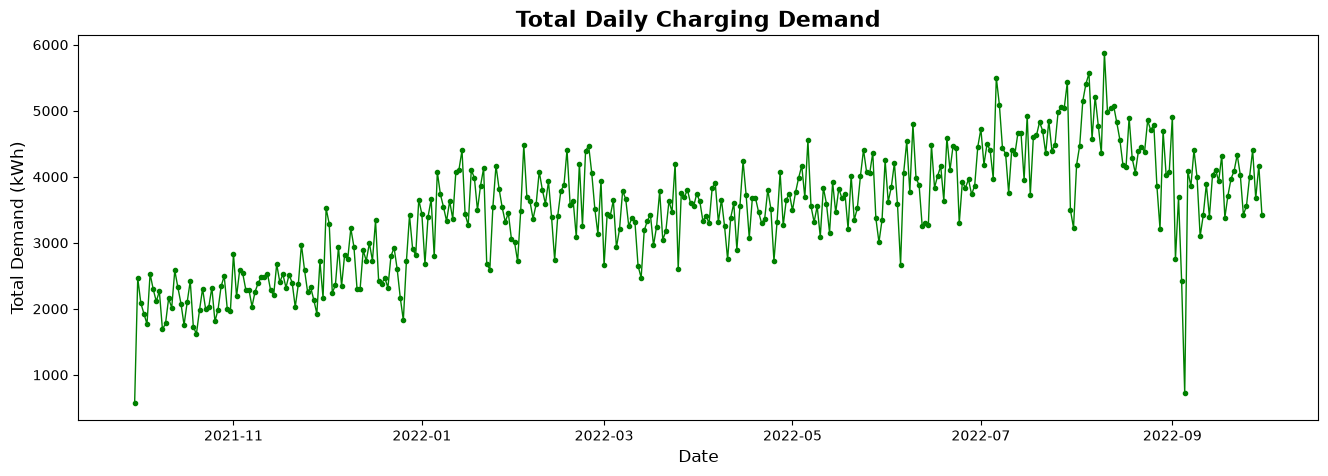

In [13]:
# Average Daily Demand

plt.figure(figsize=(16, 5))
plt.plot(daily_demand.index, daily_demand.values, marker='.', color='g', linewidth=1)

# Add titles and labels
plt.title('Total Daily Charging Demand', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Demand (kWh)', fontsize=12)

# Rotate date labels for better readability
#plt.xticks(rotation=45)
#plt.tight_layout()

# Show the plot
plt.show()

In [14]:
# Hourly Demand

early_morning = hourly_demand.between_time('12:00', '08:59')
work_hours    = hourly_demand.between_time('09:01', '18:00')
night_shift   = hourly_demand.between_time('18:01', '23:59')

# 2. Print summary statistics for a quick overview
print(f"12 AM - 9 AM Demand Total: {early_morning.sum():,.2f} kWh")
print(f"9 AM - 6 PM Demand Total: {work_hours.sum():,.2f} kWh")
print(f"6 PM - 12 PM Demand Total: {night_shift.sum():,.2f} kWh")


12 AM - 9 AM Demand Total: 1,124,168.21 kWh
9 AM - 6 PM Demand Total: 613,097.50 kWh
6 PM - 12 PM Demand Total: 410,906.62 kWh


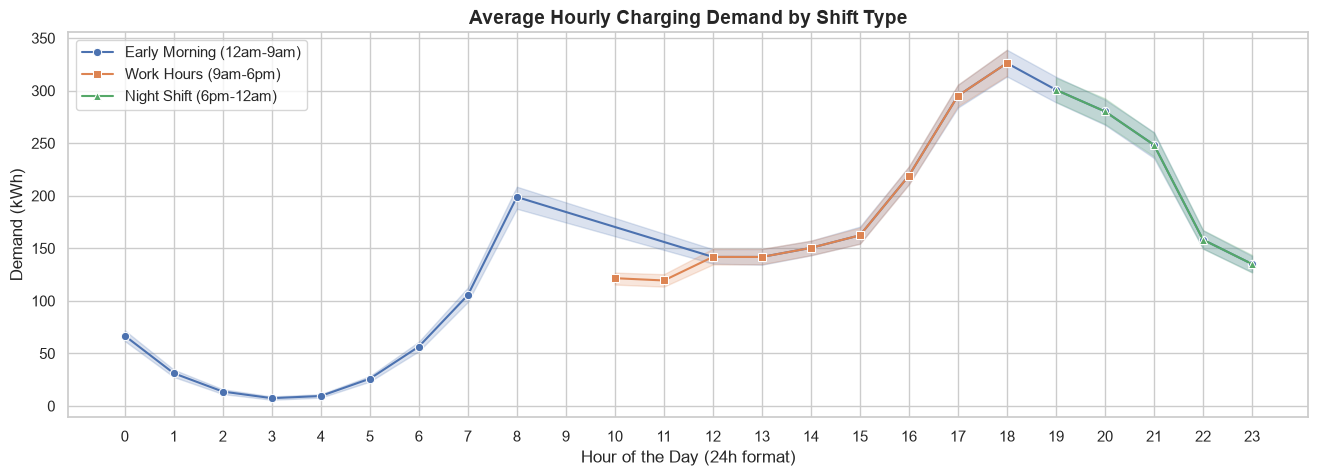

In [57]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 5))

# Calculate the average demand per hour of the day for each shift
sns.lineplot(x=early_morning.index.hour, y=early_morning.values, label='Early Morning (12am-9am)', marker='o')
sns.lineplot(x=work_hours.index.hour, y=work_hours.values, label='Work Hours (9am-6pm)', marker='s')
sns.lineplot(x=night_shift.index.hour, y=night_shift.values, label='Night Shift (6pm-12am)', marker='^')

plt.title('Average Hourly Charging Demand by Shift Type', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day (24h format)', fontsize=12)
plt.ylabel('Demand (kWh)', fontsize=12)
plt.xticks(list(range(0, 24)))
#plt.legend()
#plt.tight_layout()
plt.show()

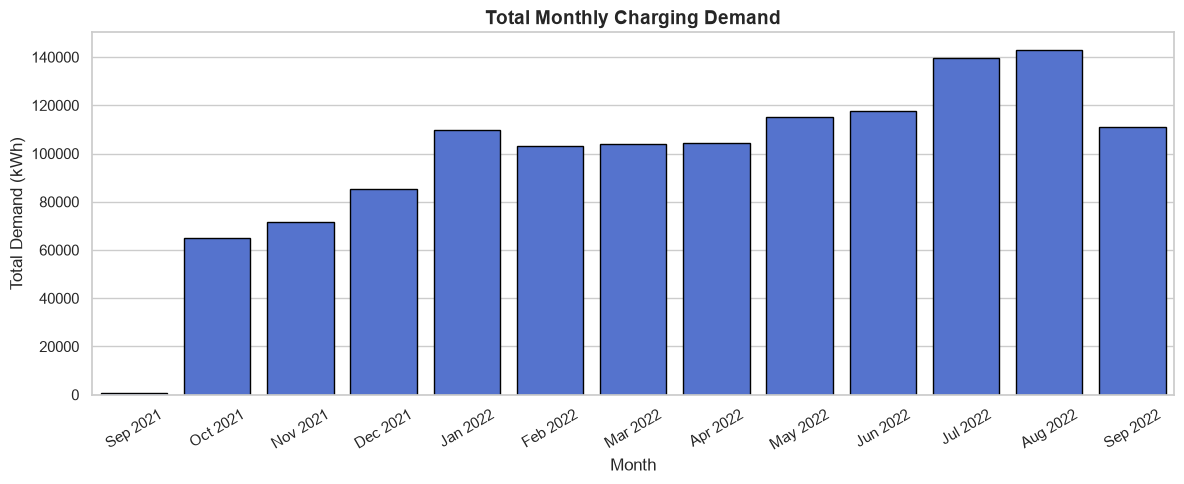

In [15]:
# Monthly Demand

monthly_demand = hourly_demand.resample('ME').sum()

# 2. Plotting the monthly demand
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

# Generate short month names for clean X-axis labels (e.g., 'Jan 2026')
month_labels = monthly_demand.index.strftime('%b %Y')

# Create the bar plot
sns.barplot(x=month_labels, y=monthly_demand.values, color='royalblue', edgecolor='black')

# Add titles and formatting
plt.title('Total Monthly Charging Demand', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Demand (kWh)', fontsize=12)

# Rotate labels slightly if you have many months of data
plt.xticks(rotation=30)
plt.tight_layout()

# Show the plot
plt.show()

Average Daily Weekday Demand: 2,560.92 kWh
Average Daily Weekend Demand: 928.36 kWh


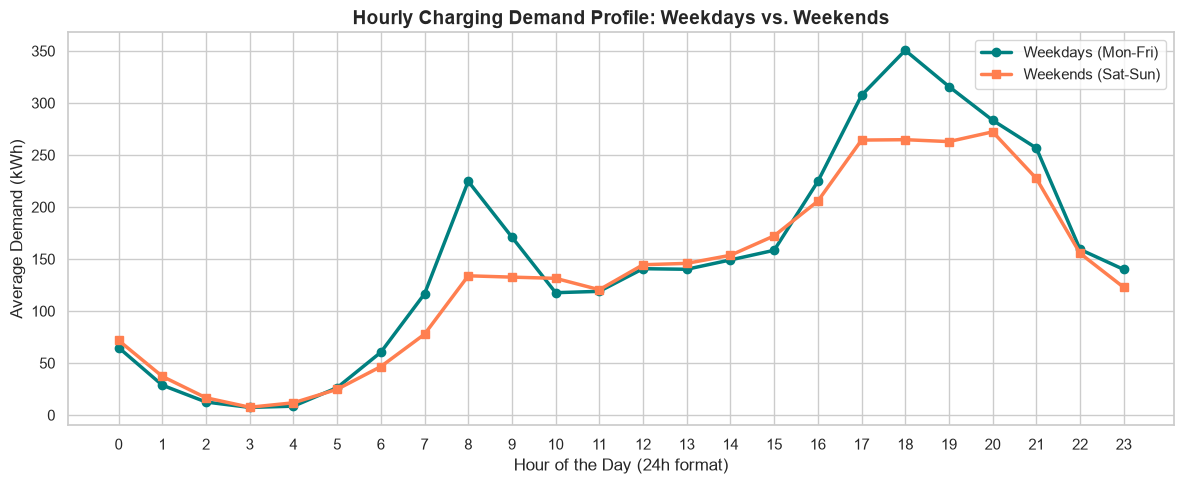

In [16]:
# Weekday and Weekends

is_weekday = hourly_demand.index.weekday < 5

# 2. Split the data into Weekdays and Weekends
weekday_demand = hourly_demand[is_weekday]
weekend_demand = hourly_demand[~is_weekday]

# 3. Calculate average hourly demand profiles for a standard 24-hour day
weekday_hourly_avg = weekday_demand.groupby(weekday_demand.index.hour).mean()
weekend_hourly_avg = weekend_demand.groupby(weekend_demand.index.hour).mean()

# 4. Print overall total comparisons
print(f"Average Daily Weekday Demand: {weekday_demand.resample('D').sum().mean():,.2f} kWh")
print(f"Average Daily Weekend Demand: {weekend_demand.resample('D').sum().mean():,.2f} kWh")

# 5. Visualization: Plotting the hourly profile overlay
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

plt.plot(weekday_hourly_avg.index, weekday_hourly_avg.values, label='Weekdays (Mon-Fri)', color='teal', linewidth=2.5, marker='o')
plt.plot(weekend_hourly_avg.index, weekend_hourly_avg.values, label='Weekends (Sat-Sun)', color='coral', linewidth=2.5, marker='s')

# Formatting the chart
plt.title('Hourly Charging Demand Profile: Weekdays vs. Weekends', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day (24h format)', fontsize=12)
plt.ylabel('Average Demand (kWh)', fontsize=12)
plt.xticks(list(range(0, 24)))
plt.legend(fontsize=11)
plt.tight_layout()

# Show the plot
plt.show()

In [17]:
# Simple Moving Average Forecast

sma_forecast = hourly_demand.rolling(window=24).mean().shift(1)

print(f"Simple Forecast after 24 Hours, Hourly: \n\n{sma_forecast}")

next_sma_pred = hourly_demand.iloc[-24:].mean()

print(f"\nSimple Moving Average: {next_sma_pred:.2f} kWh")

Simple Forecast after 24 Hours, Hourly: 

StartDatetime
2021-09-30 17:00:00           NaN
2021-09-30 18:00:00           NaN
2021-09-30 19:00:00           NaN
2021-09-30 20:00:00           NaN
2021-09-30 21:00:00           NaN
                          ...    
2022-09-30 19:00:00    181.566250
2022-09-30 20:00:00    174.746667
2022-09-30 21:00:00    169.542083
2022-09-30 22:00:00    155.546250
2022-09-30 23:00:00    148.545000
Freq: h, Name: Demand, Length: 8767, dtype: float64

Simple Moving Average: 142.78 kWh


In [18]:
# Exponential Smoothing Forecast

ewma_forecast = hourly_demand.ewm(alpha=0.2, adjust=False).mean().shift(1)

print(f"Exponential Hourly Forecast: \n\n{ewma_forecast}")

next_hour_prediction = ewma_forecast.iloc[-1]

# 3. Create the future timestamp label
next_hour_time = hourly_demand.index[-1] + pd.Timedelta(hours=1)

print(f"\n\nPredicted charging demand for {next_hour_time} is: {next_hour_prediction:.2f} kWh")

Exponential Hourly Forecast: 

StartDatetime
2021-09-30 17:00:00           NaN
2021-09-30 18:00:00     27.680000
2021-09-30 19:00:00     40.860000
2021-09-30 20:00:00     38.722000
2021-09-30 21:00:00     40.377600
                          ...    
2022-09-30 19:00:00    227.517782
2022-09-30 20:00:00    217.256225
2022-09-30 21:00:00    218.958980
2022-09-30 22:00:00    188.513184
2022-09-30 23:00:00    156.832547
Freq: h, Name: Demand, Length: 8767, dtype: float64


Predicted charging demand for 2022-10-01 00:00:00 is: 156.83 kWh


In [ ]:
# 1. Combine your existing variables into a single DataFrame to align them perfectly
eval_df = pd.DataFrame({
    'Actual': hourly_demand,
    'SMA_Pred': sma_forecast,
    'EWMA_Pred': ewma_forecast
}).dropna() # Automatically removes rows where predictions or actuals have missing values (NaN)

# 2. Extract clean arrays for calculation
y_true = eval_df['Actual'].to_numpy()
y_sma  = eval_df['SMA_Pred'].to_numpy()
y_ewma = eval_df['EWMA_Pred'].to_numpy()

# 3. Compute MAE (Mean Absolute Error)
mae_sma  = np.mean(np.abs(y_true - y_sma))
mae_ewma = np.mean(np.abs(y_true - y_ewma))

# 4. Compute RMSE (Root Mean Squared Error)
rmse_sma  = np.sqrt(np.mean((y_true - y_sma) ** 2))
rmse_ewma = np.sqrt(np.mean((y_true - y_ewma) ** 2))

# 5. Display Results Table
print("====================================================")
print("             FINAL METRICS EVALUATION               ")
print("====================================================")
print(f"Simple Moving Average (SMA):")
print(f"  -> MAE:  {mae_sma:.2f} kWh")
print(f"  -> RMSE: {rmse_sma:.2f} kWh\n")
print(f"Exponential Smoothing (EWMA):")
print(f"  -> MAE:  {mae_ewma:.2f} kWh")
print(f"  -> RMSE: {rmse_ewma:.2f} kWh")
print("====================================================")

             FINAL METRICS EVALUATION               
Simple Moving Average (SMA):
  -> MAE:  94.20 kWh
  -> RMSE: 118.88 kWh

Exponential Smoothing (EWMA):
  -> MAE:  89.07 kWh
  -> RMSE: 113.09 kWh
